In [ ]:
# 7. Implement a CNN model to recognize different alphabet hand gestures. 
# Use Conv2D, MaxPooling2D, Flatten and Dense layers. Evaluate the 
# model using test data and display predicted alphabet labels for five test 
# # images. 

In [1]:
# Step 1: Import required libraries

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [2]:
# Step 2: Load the dataset

train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

print("Training Data Shape:", train_data.shape)
print("Testing Data Shape:", test_data.shape)

Training Data Shape: (27455, 785)
Testing Data Shape: (7172, 785)


In [3]:
# Step 3: Separate features and labels

X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27455, 784)
y_train: (27455,)
X_test: (7172, 784)
y_test: (7172,)


In [4]:
# Step 4: Convert labels into 24 classes

classes = np.sort(np.unique(y_train))

label_map = {
    label: i for i, label in enumerate(classes)
}

y_train = np.array([label_map[x] for x in y_train])
y_test = np.array([label_map[x] for x in y_test])

# Alphabet names excluding J and Z

label_names = [
    chr(i + 65) for i in range(26) if i not in [9, 25]
]

print("Total Classes:", len(label_names))
print("Alphabet Labels:", label_names)

Total Classes: 24
Alphabet Labels: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


In [5]:
# Step 5: Normalize the images

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Pixel values normalized successfully!")

Pixel values normalized successfully!


In [6]:
# Step 6: Reshape images into 28x28x1

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (27455, 28, 28, 1)
Testing Shape: (7172, 28, 28, 1)


In [7]:
# Step 7: Split the training data

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)

Training Data: (21964, 28, 28, 1)
Validation Data: (5491, 28, 28, 1)


In [8]:
# Step 8: Build CNN model

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation='relu'
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation='relu'
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(24, activation='softmax')
])

print("CNN Model Created Successfully!")

CNN Model Created Successfully!


In [9]:
# Step 9: Compile the model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [10]:
# Step 10: Display model architecture

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Step 11: Train the model

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - accuracy: 0.5181 - loss: 1.6935 - val_accuracy: 0.8461 - val_loss: 0.5925
Epoch 2/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.9033 - loss: 0.3640 - val_accuracy: 0.9543 - val_loss: 0.1970
Epoch 3/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.9777 - loss: 0.1202 - val_accuracy: 0.9896 - val_loss: 0.0687
Epoch 4/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9965 - loss: 0.0437 - val_accuracy: 0.9987 - val_loss: 0.0286
Epoch 5/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.9997 - loss: 0.0174 - val_accuracy: 0.9996 - val_loss: 0.0134
Epoch 6/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 1.0000 - loss: 0.0091 - val_accuracy: 0.9998 - val_loss: 0.0076
Epoch 7/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 1.0000 - loss: 0.0055 - val_accuracy: 1.0000 - val_loss: 0.0050
Epoch 8/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 1.0000 - loss: 0.0037 - val_acc

In [12]:
# Step 12: Evaluate the model using test data

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("\nTest Loss:", test_loss)

print("Test Accuracy: {:.2f}%".format(
    test_accuracy * 100
))

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8985 - loss: 0.4659

Test Loss: 0.4658624231815338
Test Accuracy: 89.85%


In [13]:
# Step 13: Predict alphabet labels

predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)

print("Predictions Generated Successfully!")

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
Predictions Generated Successfully!


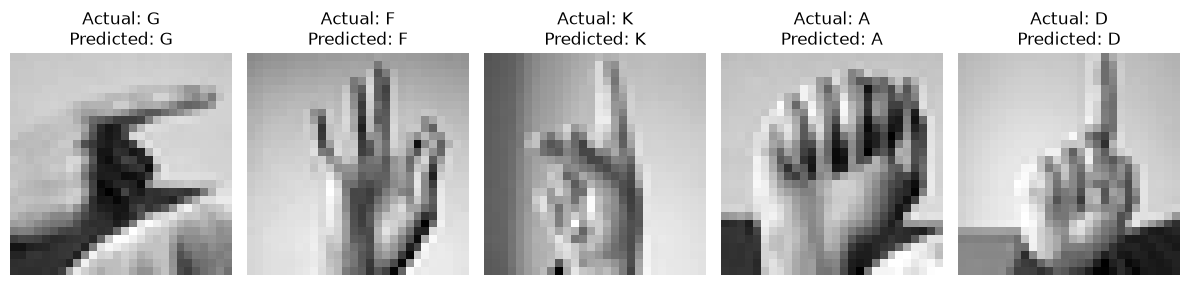

In [14]:
# Step 14: Display five test images

plt.figure(figsize=(12, 6))

for i in range(5):

    actual = label_names[y_test[i]]
    predicted = label_names[predicted_labels[i]]

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [15]:
# Step 15: Display prediction results

for i in range(5):

    print(
        "Image", i + 1,
        "| Actual:", label_names[y_test[i]],
        "| Predicted:", label_names[predicted_labels[i]]
    )

Image 1 | Actual: G | Predicted: G
Image 2 | Actual: F | Predicted: F
Image 3 | Actual: K | Predicted: K
Image 4 | Actual: A | Predicted: A
Image 5 | Actual: D | Predicted: D
